# News Topic Classifier: Owning the ML Lifecycle End to End

<img src='../docs/assets/ml_lifecycle.png' alt='ML project lifecycle' width='720'>

A news-classification prototype was built by a previous developer for a start-up's news app and was handed over for this project. It had been judged as underperforming in internal evaluation, no metrics had been recorded, and live traffic was already being scored by it. The brief: the process was to be troubleshot, a better beta was to be shipped, and a system that can be operated by the team was to be left behind.

In this notebook, that work is recorded stage by stage: **Scoping, Data, Modeling, Deployment, Monitoring**. It is intended as a companion to the codebase, not a replacement for it. The same `newsclf` package used by the CLI, the Makefile and CI is called in every cell, so no notebook-only logic is introduced here.

**How to run it:** from the project root, `pip install -e ".[dev,augment]"`, then open this notebook. If the experiment artifacts are missing it trains them (about 10 minutes on a laptop CPU); otherwise it reuses them.

## 1. Scoping

**Business problem.** The app ingests articles from a growing list of sources and has to file each one under a topic. Manual sorting does not scale with source volume, and rule-based filing produced poor results. A model that classifies an article from its title lets the team onboard sources without adding editors.

**What success looks like (agreed before touching code):**

| Level | Metric | Why it matters |
|---|---|---|
| Business | Share of articles filed automatically at **>= 95% precision** | Editors only review what the model is unsure about |
| Model | **Macro-F1** across topics (plus per-topic F1, top-2 accuracy) | Accuracy hides weak minority topics such as SCIENCE |
| Operations | Training/serving parity, rollback in one command, input drift alarms | The prototype failed silently in production |

**Feasibility and ethics questions raised with the product owner:**
* How were labels produced, by how many labellers, with what guidelines? Is inter-rater agreement measured?
* Are agreements in place with the publishers, and are users taken to the publisher's site when they click?
* What policy is applied to misinformation and to sources in unsupported languages?
* Can an article appear under more than one topic in the app? (This decides whether label ambiguity is a modeling problem or a product decision.)

**Plan and milestones (3-week proof of concept):** week 1, re-measure the prototype and audit the data; week 2, fix the data and iterate on the model with tracked experiments; week 3, versioned deployment with a canary, human-in-the-loop routing and monitoring. The prototype's title-only input is kept as a constraint for this phase.

## 2. Setup

In [1]:
import os
import sys
from pathlib import Path

# Run from the project root regardless of where Jupyter was started.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from newsclf.config import load_config, resolve
from newsclf.utils import read_json

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

cfg = load_config()
ARTIFACTS = resolve(cfg["paths"]["artifacts_dir"])
REPORTS = resolve(cfg["paths"]["reports_dir"])
print("project root:", ROOT.name)

project root: news-topic-classifier


## 3. Data

A data-centric approach is taken first: the model code is held fixed, the data is improved, and only then is effort spent on the model.

### 3.1 What was inherited

The previous developer left a single experiment folder (`E1`), which now lives in the repo as:

* `data/raw/train_data.csv`, `data/raw/test_data.csv`: the prototype's train and test splits
* `models/legacy/e1_baseline/saved_model`: the trained TensorFlow SavedModel
* `models/legacy/e1_baseline/vocab/`: `vocabulary.txt` (top 10,000 title tokens) and `labels.txt` (8 topics)
* `data/raw/news_articles.db`: a log of articles the prototype scored in production

Only `title` (input) and `topic` (label) feed the model; `link`, `domain` and `published_date` are used elsewhere in the app.

In [2]:
from newsclf.data.ingest import load_legacy_split

legacy_train = load_legacy_split(cfg, "train_data.csv")
legacy_test = load_legacy_split(cfg, "test_data.csv")
print(f"train: {legacy_train.shape}, test: {legacy_test.shape}")
legacy_train.head(10)

train: (84375, 5), test: (24399, 5)


,title,link,domain,published_date,topic
0,"NSW remains on COVID-19 high alert | The Star | Newcastle, NSW",https://www.newcastlestar.com.au/story/6878465/nsw-remains-on-covid-19-high-alert/?cs=7,newcastlestar.com.au,2020-08-13 17:32:28,HEALTH
1,Missing people: How does someone just disappear?,https://www.bbc.co.uk/news/uk-england-cambridgeshire-53648599,bbc.co.uk,2020-08-04 15:56:20,NATION
2,"An American Pickle review: In a dual role, Seth Rogen’s drama wins over comedy",https://www.polygon.com/2020/8/6/21357120/american-pickle-review-movie-seth-rogen-simon-rich-hbo-max,polygon.com,2020-08-06 15:58:22,ENTERTAINMENT
3,"Katie Spotz to Run 130 Miles to Bring Clean Water to Tanzania, Shares Testimony of Change",http://www.christianitydaily.com/articles/9647/20200807/katie-spotz-run-130-miles-bring-clean-water-tanzania-shares.htm,christianitydaily.com,2020-08-07 19:45:00,NATION
4,CDC Director Says This Fall Could Be ‘the Worst’ We’ve Ever Had Thanks to COVID-19,https://www.self.com/story/worst-fall-ever-covid,self.com,2020-08-13 19:37:52,HEALTH
5,Free water and electricity may be counterproductive – Economist,https://www.ghanaweb.com/GhanaHomePage/NewsArchive/Free-water-and-electricity-may-be-counterproductive-Economist-103...,ghanaweb.com,2020-08-11 13:25:37,NATION
6,State places Tazewell County on COVID-19 warning list,https://week.com/2020/08/07/state-places-tazewell-county-on-covid-19-warning-list/,week.com,2020-08-07 18:00:24,HEALTH
7,Over 100 people quarantined in Mississippi school district after several test positive for coronavirus,https://www.nbcnews.com/news/us-news/over-100-people-quarantined-mississippi-school-district-after-several-test-n123...,nbcnews.com,2020-08-06 16:35:00,NATION
8,How global warming is wiping out Africa's oldest baobab trees,http://www.capetalk.co.za/articles/307750/how-global-warming-is-wiping-out-africa-s-oldest-baobab-trees,capetalk.co.za,2018-06-14 12:00:53,WORLD
9,"Delay routine dental checkups, WHO urges, until COVID risk is known","https://www.thepeninsulaqatar.com/article/11/08/2020/Delay-routine-dental-checkups,-WHO-urges,-until-COVID-risk-is-k...",thepeninsulaqatar.com,2020-08-11 17:13:00,HEALTH


### 3.2 Labelling a sample

Before the labels are trusted, a slice is labelled by hand and compared against the dataset. The `topic` column is hidden, a call is made on each title, and the column is then revealed.

In [3]:
sample = legacy_train[["title", "topic"]].iloc[30:40]
sample

,title,topic
30,"28% Fall in Mumbai's Home Isolation Cases, 62% Drop in Institutional Quarantine as Covid Curve Plateaus",NATION
31,Sniffer dogs begin trials to detect Covid,HEALTH
32,Seth Rogen says Marvel blockbusters make it difficult for comedy films,ENTERTAINMENT
33,"Farewell to Pete Way, the debauched bassist with a frontman's swagger",ENTERTAINMENT
34,Poo detectives on the COVID-19 frontline,HEALTH
35,Fortnite maker challenges Apple and Google's app store rules through direct-payment discounts,TECHNOLOGY
36,Why iPhone 12 Will Be Another 'Defining Chapter' In Apple's Growth Story,BUSINESS
37,Forex auction bolsters productive sector,NATION
38,Intel Tiger Lake could outrun AMD Ryzen 4000 in single-core performance,TECHNOLOGY
39,Rappi delivery workers in Colombia's Bogota strike over conditions,TECHNOLOGY


Reading these against their labels, several are defensible under two topics:

* row 30, a Mumbai COVID isolation-case update, is labelled **NATION**; it reads just as well as HEALTH
* row 37, "Forex auction bolsters productive sector", is labelled **NATION**; it reads as BUSINESS
* row 39, Rappi delivery workers striking in Bogota, is labelled **TECHNOLOGY**; it reads as BUSINESS or WORLD
* row 36 is the iPhone headline under BUSINESS, which turns out to be a data bug (3.4)

That is the first signal that **human-level performance on this task is well below 100%** and that labelling guidelines, not just the model, set the ceiling. These questions were logged for the labelling team:

* How is each topic defined? Where is the line between SCIENCE and TECHNOLOGY, and between WORLD and NATION?
* When a story fits two topics, which rule picks one?
* Would the app support more than one topic per article?

### 3.3 Re-measure the prototype (E1 baseline)

There were no recorded metrics, so the baseline is recomputed from the shipped SavedModel and vocabulary on the shipped test file. The SavedModel predates Keras 3, so `newsclf.models.legacy` loads it through its serving signature rather than `keras.models.load_model`.

In [4]:
from newsclf.models.legacy import evaluate_legacy

e1 = read_json(ARTIFACTS / "E1" / "metrics.json") if (ARTIFACTS / "E1" / "metrics.json").exists() else evaluate_legacy(cfg)
print(f"E1 test accuracy: {e1['test']['accuracy']:.4f} | top-2: {e1['test']['top2_accuracy']:.4f} | macro-F1: {e1['test']['macro_f1']:.4f}")
pd.DataFrame(e1["test"]["per_class"]).T[["precision", "recall", "f1", "support"]].round(3)

E1 test accuracy: 0.7778 | top-2: 0.8927 | macro-F1: 0.7681


,precision,recall,f1,support
ENTERTAINMENT,0.809,0.809,0.809,3110.0
HEALTH,0.746,0.626,0.681,2273.0
TECHNOLOGY,0.886,0.803,0.843,2096.0
WORLD,0.564,0.591,0.577,2473.0
BUSINESS,1.000,1.000,1.000,3881.0
SPORTS,0.860,0.876,0.868,3486.0
NATION,0.666,0.641,0.654,3871.0
SCIENCE,0.663,0.773,0.714,3209.0


Roughly 78% accuracy. That number is recorded in the experiment ledger (`reports/experiment_tracker.csv`, plus MLflow), but a perfect 1.00 F1 is reported for BUSINESS. Perfect scores on one class of a noisy text task are to be treated as a red flag, not a win. This is revisited below.

### 3.4 Data audit

`newsclf.data.validate` runs the required checks on every dataset before it is allowed near training: schema, label set, nulls, duplicates, label conflicts, collapsed classes and class balance.

In [5]:
from newsclf.pipelines import validate_raw

audit = validate_raw(cfg)
for w in audit["warnings"]:
    print("-", w)

13:33:14 | WARNING | newsclf.pipelines | Collapsed classes (near-constant title): ['BUSINESS']. Model would learn a single string for these topics.
13:33:14 | WARNING | newsclf.pipelines | 21329 duplicate titles: leakage risk across splits.
13:33:14 | WARNING | newsclf.pipelines | 348 titles carry more than one label (label noise).
13:33:14 | WARNING | newsclf.pipelines | Minority class below 5% of rows (3.5%): monitor per-class metrics.


- Collapsed classes (near-constant title): ['BUSINESS']. Model would learn a single string for these topics.
- 21329 duplicate titles: leakage risk across splits.
- 348 titles carry more than one label (label noise).
- Minority class below 5% of rows (3.5%): monitor per-class metrics.


In [6]:
dist = pd.DataFrame({
    "train %": legacy_train.topic.value_counts(normalize=True).mul(100).round(1),
    "test %": legacy_test.topic.value_counts(normalize=True).mul(100).round(1),
}).sort_index()
dist

,train %,test %
topic,,
BUSINESS,13.2,15.9
ENTERTAINMENT,14.1,12.7
HEALTH,15.1,9.3
NATION,13.2,15.9
SCIENCE,0.7,13.2
SPORTS,13.6,14.3
TECHNOLOGY,15.3,8.6
WORLD,14.8,10.1


Four findings, each with a fix in the pipeline:

| Finding | Risk | Fix |
|---|---|---|
| **BUSINESS has a single title repeated ~15,000 times** | The model learns one string; BUSINESS "accuracy" is fake | Repair titles (3.6) |
| **~21k duplicate titles** across the files | Train/test leakage inflates every metric | De-duplicate before splitting |
| **~350 titles carry more than one label** | Label noise | Majority vote, and raised with the labelling team |
| **Train/test class mix differs** (SCIENCE is 0.7% of train but 13% of test) | Model barely learns SCIENCE and is graded mostly on it | Pool and re-split, stratified on topic |

### 3.5 The data pipeline adopted

<center><img src='../docs/assets/pipeline_diagram.png' alt='pipeline' width='640'></center>

Every transformation from raw file to prediction is code, versioned and reproducible:

| Stage | Module | Output |
|---|---|---|
| Ingest | `data/ingest.py` | raw rows + `source_file` lineage |
| Validate | `data/validate.py` | findings report, hard failures raise |
| Repair | `data/repair.py` | restored BUSINESS titles, `title_source` column |
| De-duplicate | `data/prepare.py` | one row per normalised title |
| Split | `data/prepare.py` | stratified 60/20/20 train/dev/test |
| Version | `data/prepare.py` | `data/processed/<hash>/` + `manifest.json` (file hashes, reports) |
| Vectorize | `features/text.py` | vocabulary fitted on **train only**, saved with the model |

The processed folder name is a hash of the data config, so two experiments that share data settings share identical split files, and changing a data setting can never overwrite an earlier dataset.

### 3.6 Experiment 2: rebalanced split (data still unrepaired)

First the data is only pooled and re-split, stratified on topic, with the prototype model kept. In this way the effect of the split is isolated.

In [7]:
from newsclf.data.prepare import load_manifest, load_splits, prepare_dataset

e2_dir = prepare_dataset(load_config("E2"))
e2_splits = load_splits(e2_dir)
pd.DataFrame({name: df.topic.value_counts(normalize=True).mul(100).round(1) for name, df in e2_splits.items()}).sort_index()

13:33:14 | INFO    | newsclf.data.prepare | Reusing processed dataset data/processed/710f45e524


,train,dev,test
topic,,,
BUSINESS,13.8,13.8,13.8
ENTERTAINMENT,13.8,13.8,13.8
HEALTH,13.8,13.8,13.8
NATION,13.8,13.8,13.8
SCIENCE,3.5,3.5,3.5
SPORTS,13.8,13.8,13.8
TECHNOLOGY,13.8,13.8,13.8
WORLD,13.8,13.8,13.8


The topic mix is now identical across train, dev and test. Note SCIENCE remains a minority class (~3%) overall; that will need watching in per-topic metrics.

### 3.7 Experiment 3 data: repair, de-duplicate, leak-free split

The links survived the encoding accident, and news URLs almost always carry the headline as a slug. `newsclf.data.repair` rebuilds titles from a trusted reference file when one is supplied (`data.reference_titles_file`, e.g. the original `.backup.csv`), and from the URL slug otherwise. Rows with no usable slug are dropped.

In [8]:
from newsclf.data.repair import title_from_url

business = legacy_train[legacy_train.topic == "BUSINESS"].head(8)
pd.DataFrame({"stored title": business.title.str[:45] + "...", "recovered from URL": business.link.map(title_from_url)})

,stored title,recovered from URL
14,Why iPhone 12 Will Be Another 'Defining Chapt...,indian american student randeep hothi sues tesla ceo elon musk
18,Why iPhone 12 Will Be Another 'Defining Chapt...,NaN
19,Why iPhone 12 Will Be Another 'Defining Chapt...,gold price analysis xau usd bulls jostle with bears beyond
23,Why iPhone 12 Will Be Another 'Defining Chapt...,china set step testing countrys fastest ever maglev train top
24,Why iPhone 12 Will Be Another 'Defining Chapt...,southwest airlines coronavirus cleaning
25,Why iPhone 12 Will Be Another 'Defining Chapt...,energy names rise crude oil on stimulus hopes demand recovery
36,Why iPhone 12 Will Be Another 'Defining Chapt...,british report suggests suvs are the new smoking
45,Why iPhone 12 Will Be Another 'Defining Chapt...,sf holding self operated model supports resilience market share


In [9]:
e3_dir = prepare_dataset(load_config("E3"))
m3 = load_manifest(e3_dir)
print("repair:", m3["repair"])
print("dedup :", m3["deduplication"])
print("titles shared across splits:", m3["split_validation"]["title_overlap"])
print("rows  :", {k: v["rows"] for k, v in m3["files"].items()})

13:33:14 | INFO    | newsclf.data.prepare | Reusing processed dataset data/processed/70d8866e05


repair: {'collapsed_classes': ['BUSINESS'], 'from_reference': 0, 'from_slug': 14009, 'dropped': 991}
dedup : {'rows_before': 107783, 'rows_after': 100928, 'conflicting_titles_resolved': 407}
titles shared across splits: {'train_vs_dev': 0, 'train_vs_test': 0, 'dev_vs_test': 0}
rows  : {'train': 60552, 'dev': 20184, 'test': 20184}


Zero titles are shared between train, dev and test, so dev and test now measure generalisation rather than recall. Slug titles lose punctuation and casing, which the vectorizer strips anyway; the trade-off is recorded in the model card.

## 4. Modeling

<img src='../docs/assets/ml_lifecycle_modeling.png' alt='modeling stage' width='640'>

All runs are config-driven (`configs/base.yaml` + `configs/experiments/E*.yaml`) and logged to the CSV ledger and MLflow. If the artifacts are missing, the next cell trains every experiment.

In [10]:
from newsclf.config import list_experiments
from newsclf.pipelines import leaderboard, run_all

RETRAIN = False  # set True to retrain everything from scratch
expected = ["E1", "B1", *list_experiments()]
if RETRAIN or not all((ARTIFACTS / e / "metrics.json").exists() for e in expected):
    run_all(cfg)

metrics = {e: read_json(ARTIFACTS / e / "metrics.json") for e in expected}
print("experiments available:", list(metrics))

experiments available: ['E1', 'B1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8']


### 4.1 E2: the number went up. Is it real?

In [11]:
def per_topic(name, split="dev"):
    return pd.DataFrame(metrics[name][split]["per_class"]).T[["precision", "recall", "f1"]].round(3)

print(f"E2 test accuracy: {metrics['E2']['test']['accuracy']:.4f}")
per_topic("E2")

E2 test accuracy: 0.8146


,precision,recall,f1
BUSINESS,1.000,1.000,1.000
ENTERTAINMENT,0.812,0.851,0.831
HEALTH,0.773,0.814,0.793
NATION,0.646,0.627,0.637
SCIENCE,0.860,0.776,0.816
SPORTS,0.903,0.872,0.887
TECHNOLOGY,0.879,0.871,0.875
WORLD,0.638,0.636,0.637


Accuracy rose from ~78% to ~81% just from the split, but BUSINESS still scores a perfect F1. Looking at the training rows explains it:

In [12]:
e2_splits["train"].query("topic == 'BUSINESS'")[["title", "link"]].head(5)

,title,link
3,Why iPhone 12 Will Be Another 'Defining Chapter' In Apple's Growth Story,https://www.globenewswire.com/news-release/2020/08/14/2078857/0/en/Resverlogix-Announces-Private-Placement.html
14,Why iPhone 12 Will Be Another 'Defining Chapter' In Apple's Growth Story,https://www.fool.com/investing/2020/08/04/will-moderna-get-away-with-charging-50-more-than-p.aspx
23,Why iPhone 12 Will Be Another 'Defining Chapter' In Apple's Growth Story,https://www.businesswire.com/news/home/20200810005603/en/Global-Neurology-Devices-Market-2019-2025--
31,Why iPhone 12 Will Be Another 'Defining Chapter' In Apple's Growth Story,https://www.globenewswire.com/news-release/2020/08/12/2076884/0/en/Directorate-change.html
55,Why iPhone 12 Will Be Another 'Defining Chapter' In Apple's Growth Story,https://www.csrwire.com/press_releases/45605-Culture-of-Care-and-Camaraderie-Makes-Bacardi-U-S-A-Inc-Great-Place-to-...


Every BUSINESS row has the same title. The model is matching one string. This is why E2 is automatically **non-promotable**: its dataset fails the data-quality gate (collapsed class, titles shared across splits), regardless of its score.

### 4.2 E3: same model, clean data

In [13]:
compare = pd.DataFrame({e: {"test_accuracy": metrics[e]["test"]["accuracy"], "test_macro_f1": metrics[e]["test"]["macro_f1"],
                            "data_quality_passed": (metrics[e].get("data_quality") or {}).get("passed")} for e in ["E2", "E3"]}).T
display(compare)
per_topic("E3")

,test_accuracy,test_macro_f1,data_quality_passed
E2,0.814646,0.813452,False
E3,0.754261,0.752717,True


,precision,recall,f1
BUSINESS,0.792,0.765,0.778
ENTERTAINMENT,0.790,0.845,0.817
HEALTH,0.698,0.771,0.732
NATION,0.624,0.626,0.625
SCIENCE,0.832,0.689,0.754
SPORTS,0.895,0.874,0.884
TECHNOLOGY,0.824,0.852,0.838
WORLD,0.661,0.590,0.624


The headline number drops, and that is the correct outcome: E3 is the first honest measurement of the prototype architecture. BUSINESS now has to be learned from real headlines, and nothing in the test set was seen in training.

### 4.3 Error analysis: where is the model wrong, and is it really wrong?

In [14]:
pd.read_csv(ARTIFACTS / "E3" / "reports" / "top_confusions_dev.csv")

,topic,predicted,count,share_of_errors
0,WORLD,NATION,535,0.1098
1,NATION,WORLD,431,0.0885
2,NATION,HEALTH,275,0.0565
3,WORLD,HEALTH,238,0.0489
4,HEALTH,NATION,197,0.0404
5,BUSINESS,TECHNOLOGY,157,0.0322
6,BUSINESS,NATION,150,0.0308
7,WORLD,ENTERTAINMENT,149,0.0306
8,HEALTH,WORLD,146,0.0300
9,NATION,ENTERTAINMENT,133,0.0273


In [15]:
errors = pd.read_csv(ARTIFACTS / "E3" / "reports" / "errors_dev_sample.csv")
errors[errors.predicted == "NATION"][["title", "topic", "predicted", "second_guess", "confidence"]].head(10)

,title,topic,predicted,second_guess,confidence
5,SANDF will not apply force - Defence Minister,WORLD,NATION,WORLD,0.918800
6,"Man struck, injured by escaping car burglar in west El Paso",HEALTH,NATION,HEALTH,0.815766
8,UK to axe public health agency for COVID-19 response,HEALTH,NATION,HEALTH,0.597806
11,Jamaica's High Court Rules School Can Ban Dreadlocks,WORLD,NATION,WORLD,0.854921
14,indian oils rs 13805 crore new plant in odisha by 2024,BUSINESS,NATION,BUSINESS,0.781510
28,Risk of Rain 2 Mithrix guide: how to unlock Captain,TECHNOLOGY,NATION,TECHNOLOGY,0.633065
33,Ram Mandir: Why a 120-year-old Tagore poem is going viral,ENTERTAINMENT,NATION,WORLD,0.763080
34,More than dozen U.S. states expected to sue Trump administration over postal cuts,WORLD,NATION,WORLD,0.433550
47,Criterium du Dauphine: Primoz Roglic hail storm damage after Stage 2 result,SPORTS,NATION,SPORTS,0.359612
53,‘Spiritual Problem’ Fraud: I duped couple N3.5m not N5m ― Beninoise claims,WORLD,NATION,ENTERTAINMENT,0.980091


The dominant confusions are WORLD/NATION and SCIENCE/TECHNOLOGY/HEALTH, and many "errors" are titles a human would also hesitate on (a COVID case count in a US county reads as both HEALTH and NATION). If the labelling guidelines cannot pick one topic deterministically, the model is being graded against a coin flip. Two remedies, both needing product-owner buy-in:

1. **Multi-label annotation**: let labellers tick every topic that applies.
2. **Merge overlapping topics**: WORLD+NATION and SCIENCE+TECHNOLOGY (tested as E8 below).

Top-2 accuracy is a quick proxy for how much of the error is ambiguity:

In [16]:
top2 = pd.DataFrame({t: {"top1_recall": v["recall"], "top2_recall": v["top2_recall"]}
                     for t, v in metrics["E3"]["dev"]["per_class"].items()}).T
top2["gain"] = top2.top2_recall - top2.top1_recall
top2.sort_values("gain", ascending=False).round(3)

,top1_recall,top2_recall,gain
WORLD,0.590,0.831,0.241
NATION,0.626,0.843,0.217
HEALTH,0.771,0.895,0.124
SCIENCE,0.689,0.799,0.110
BUSINESS,0.765,0.873,0.107
ENTERTAINMENT,0.845,0.920,0.076
TECHNOLOGY,0.852,0.920,0.068
SPORTS,0.874,0.922,0.048


WORLD and NATION gain the most when the second guess counts: the model usually has the right answer in its top two, which points at label ambiguity more than at model capacity.

### 4.4 Improving the model and the data

With clean data in place, both sides were iterated on, one change per experiment:

| Exp | Change | Hypothesis |
|---|---|---|
| E4 | Pooled embeddings (avg + max) instead of Flatten, 20k vocab, dropout, balanced class weights, early stopping | Flatten ties weights to token *positions*; pooling generalises across headline lengths; class weights lift SCIENCE |
| E5 | E4 + EDA augmentation (synonym replacement, random insertion, swap, deletion) on SCIENCE, **train split only** | More minority-class variety |
| E6 | Bidirectional LSTM | Word order matters |
| E7 | 1D CNN + stop-word removal in the vectorizer | n-gram detectors; stop words are noise |
| E8 | E4 with merged taxonomy (6 topics) | Quantify the cost of label ambiguity (study only, not promotable) |
| B1 | TF-IDF word + char n-grams, logistic regression | Is the neural model earning its complexity? |

In [17]:
from newsclf.data.augment import EDAAugmenter, wordnet_synonyms

aug = EDAAugmenter(alpha=0.2, synonyms=wordnet_synonyms(), seed=7)
title = "NASA telescope captures rare image of distant galaxy collision"
print("ops:", [op.__name__ for op in aug.ops])
for t in aug.augment(title, 4):
    print(" ->", t)

ops: ['synonym_replacement', 'random_insertion', 'random_swap', 'random_deletion']
 -> NASA telescope captures rare image of distant extragalactic nebula collision
 -> NASA telescope captures rare image of distant galaxy national aeronautics and space administration collision
 -> telescope NASA captures rare image of distant galaxy collision
 -> NASA rare image distant galaxy collision


In [18]:
board = leaderboard(cfg)
board[["experiment", "model", "classes", "dev_macro_f1", "test_acc", "test_top2", "test_macro_f1",
       "test_SCIENCE_f1", "auto_coverage@95%", "data_quality_passed", "promotable"]].round(4)

,experiment,model,classes,dev_macro_f1,test_acc,test_top2,test_macro_f1,test_SCIENCE_f1,auto_coverage@95%,data_quality_passed,promotable
0,B1,tfidf_logreg,8,0.8156,0.8189,0.9274,0.8210,0.8493,NaN,None,False
1,E1,legacy_dense (inherited SavedModel),8,NaN,0.7778,0.8927,0.7681,0.7137,NaN,None,False
2,E2,legacy_dense,8,0.8095,0.8146,0.9221,0.8135,0.8046,0.6251,False,False
3,E3,legacy_dense,8,0.7565,0.7543,0.8850,0.7527,0.7610,0.4652,True,True
4,E4,pooled,8,0.7933,0.7951,0.9077,0.7946,0.8041,0.5509,True,True
5,E5,pooled,8,0.7912,0.7888,0.9055,0.7897,0.8283,0.5386,True,True
6,E6,bilstm,8,0.7703,0.7775,0.8968,0.7739,0.7711,0.5177,True,True
7,E7,cnn,8,0.7734,0.7739,0.8961,0.7717,0.7738,0.4965,True,True
8,E8,pooled,6,0.8402,0.8456,0.9461,0.8448,NaN,0.6892,True,False


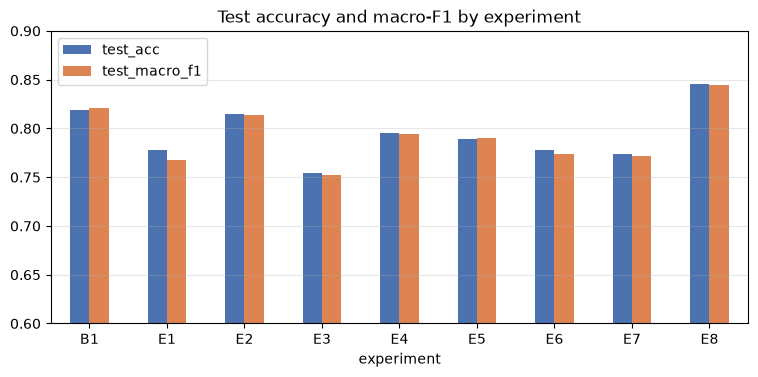

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.8))
plot = board.set_index("experiment")[["test_acc", "test_macro_f1"]].sort_index()
plot.plot.bar(ax=ax, rot=0, color=["#4C72B0", "#DD8452"])
ax.set_ylim(0.6, 0.9)
ax.set_title("Test accuracy and macro-F1 by experiment")
ax.grid(axis="y", alpha=0.3)
plt.show()

### 4.5 Reading the leaderboard

* **E3 -> E4** is the biggest model-side gain: pooling, regularisation and class weights.
* **E5** augmentation did not beat E4 on dev macro-F1. The capability is kept (it is one config switch) but is not used in the champion; real extra SCIENCE data beats synthetic paraphrases.
* **E6/E7** heavier architectures do not beat the simple pooled model on 10-20 token headlines.
* **B1** (TF-IDF + logistic regression) edges out every neural model. That is a useful, honest result: the title-only task is near its ceiling, and the next gains come from data and labels, not architecture.
* **E8** shows how much of the remaining error is taxonomy: merging the overlapping topics lifts accuracy by several points. That number goes to the product owner.

**Champion selection rule:** best *dev* macro-F1 among promotable runs (same label space, passed the data-quality gate). Test metrics are reported but never used to choose.

{'experiment': 'E4', 'selection_metric': 'dev_macro_f1', 'dev_macro_f1': 0.7933247029807081, 'test_macro_f1': 0.7945863803152653, 'test_accuracy': 0.7950852160126833}


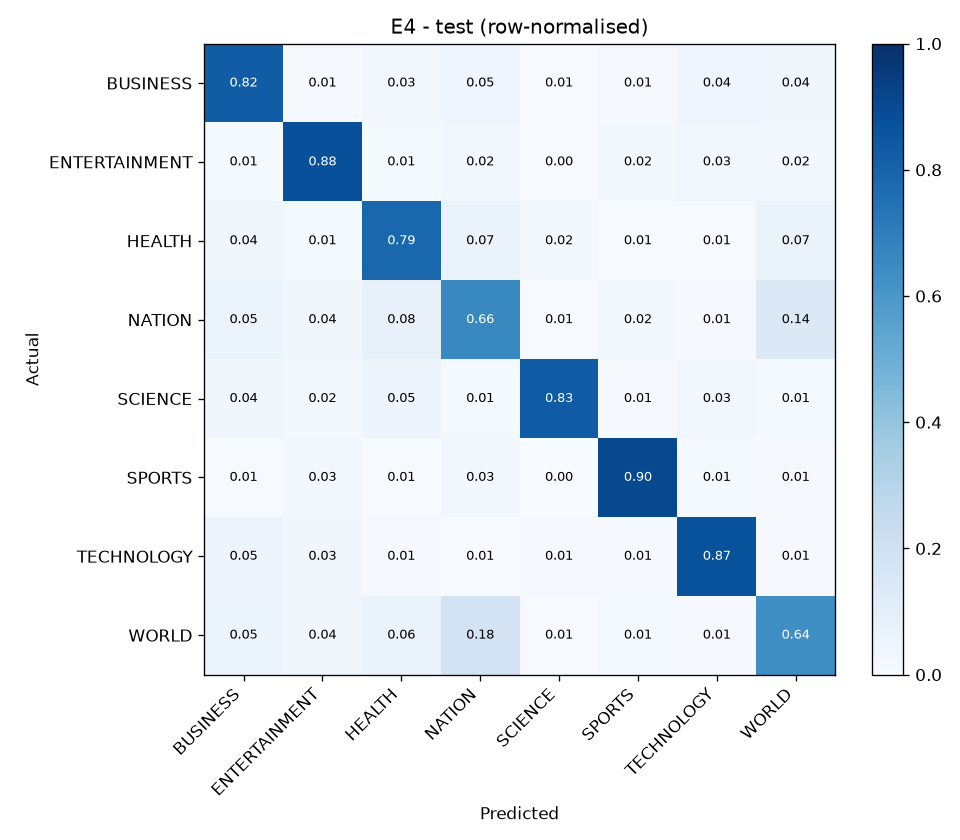

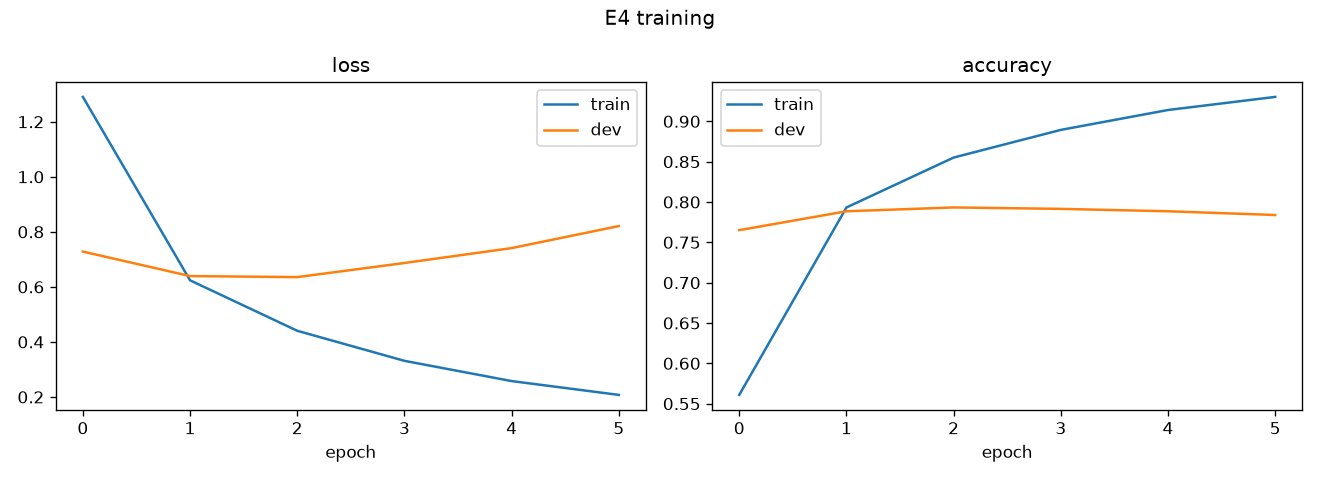

In [20]:
champion = read_json(REPORTS / "champion.json")
print(champion)
CHAMP = champion["experiment"]
display(Image(filename=str(ARTIFACTS / CHAMP / "reports" / "confusion_matrix_test.png"), width=560))
display(Image(filename=str(ARTIFACTS / CHAMP / "reports" / "training_curves.png"), width=760))

## 5. Deployment

<img src='../docs/assets/network.png' alt='system' width='640'>

In the production system, articles are scored in hourly batches. Models are deployed with TensorFlow Serving, versioned, with labels for **stable**, **canary** and **deprecated**.

### 5.1 Training/serving skew: why the vectorizer ships inside the model

The prototype expected clients to tokenize titles themselves with the right vocabulary file. Here is what happens when a client loads the wrong one (the champion's vocabulary instead of the prototype's):

In [21]:
import numpy as np
import tensorflow as tf
from newsclf.features.text import build_vectorizer, load_vocabulary
from newsclf.models.legacy import LegacyModel

legacy = LegacyModel(cfg["paths"]["legacy_model_dir"])
y = legacy_test.topic.map({l: i for i, l in enumerate(legacy.labels)}).to_numpy()
right = legacy.predict_proba(legacy_test.title).argmax(1)

legacy.vectorizer = build_vectorizer({"max_tokens": 10000, "sequence_length": 20},
                                     load_vocabulary(ARTIFACTS / CHAMP / "vocab" / "vocabulary.txt")[:10000])
wrong = legacy.predict_proba(legacy_test.title).argmax(1)
print(f"correct vocabulary: {(right == y).mean():.1%} accuracy")
print(f"wrong vocabulary  : {(wrong == y).mean():.1%} accuracy  <- no error raised, just silently bad predictions")

correct vocabulary: 77.8% accuracy
wrong vocabulary  : 13.2% accuracy  <- no error raised, just silently bad predictions


No exception, just quietly wrong predictions. For this reason, **raw strings** are taken by every exported model: `newsclf.serving.export` attaches the fitted `TextVectorization` layer in front of the network and writes a SavedModel with a `serving_default(title: string[]) -> probabilities` signature, plus `assets.extra/` holding the labels, vocabulary and model card.

### 5.2 Versioned deployment with a registry

`serving/registry.json` is the single source of truth for versions and labels. Both TF Serving configs (native binary and Docker) are generated from it. The bootstrap state mirrors reality: the inherited prototype is what production runs today (**stable**), and the champion goes out as **canary**.

In [22]:
from newsclf.pipelines import deploy

print(deploy(cfg))
print((resolve(cfg["paths"]["serving_root"]) / "models.docker.config").read_text())

13:33:19 | INFO    | newsclf.serving.export | Serving directory and registry reset
13:33:19 | INFO    | newsclf.serving.registry | Promoted version 1 to stable (previous stable: None)
13:33:19 | INFO    | newsclf.serving.export | Registered legacy prototype as version 1 (stable)
13:33:20 | INFO    | newsclf.serving.export | Exported E4 as newsapp_model version 2 (canary)


{'labels': {'stable': 1, 'canary': 2}, 'versions': {1: 'E1', 2: 'E4'}}
# GENERATED by `newsclf` from serving/registry.json - do not edit by hand.
model_config_list {
  config {
    name: 'newsapp_model'
    base_path: '/models/newsapp_model'
    model_platform: 'tensorflow'
    model_version_policy {
      specific {
          versions: 1
          versions: 2
      }
    }
    version_labels {
      key: 'stable'
      value: 1
    }
    version_labels {
      key: 'canary'
      value: 2
    }
  }
}



### 5.3 Serving over REST

TF Serving runs in Docker (`docker compose -f serving/docker-compose.yml up -d`, see 5.7). For a self-contained notebook, the project's local TF-Serving-compatible server is started, which serves the same version folders with the same URL scheme, so every request below works unchanged against real TF Serving on port 8501.

In [23]:
import json
import subprocess
import time

import requests

PORT = 8502
BASE = f"http://localhost:{PORT}"
server = subprocess.Popen([sys.executable, "-m", "newsclf", "serve", "--port", str(PORT)], cwd=ROOT,
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(60):
    try:
        if requests.get(f"{BASE}/health", timeout=1).ok:
            break
    except requests.ConnectionError:
        time.sleep(1)
print(requests.get(f"{BASE}/v1/models/newsapp_model").json())

{'model_version_status': [{'version': '2', 'state': 'AVAILABLE', 'status': {'error_code': 'OK', 'error_message': ''}}, {'version': '1', 'state': 'AVAILABLE', 'status': {'error_code': 'OK', 'error_message': ''}}]}


In [24]:
def predict(instances, label):
    r = requests.post(f"{BASE}/v1/models/newsapp_model/labels/{label}:predict",
                      data=json.dumps({"instances": instances}), headers={"content-type": "application/json"})
    return r.status_code, r.json()

# Stable (legacy prototype) only understands 20 token ids...
print(predict([[1] * 20], "stable"))
# ...and rejects raw text, exactly like TF Serving would.
print(predict(["sample title"], "stable"))

(200, {'predictions': [[0.1550125926733017, 0.08718496561050415, 0.09149865061044693, 0.12575368583202362, 0.013613540679216385, 0.1664850115776062, 0.23662389814853668, 0.12382758408784866]]})
(400, {'error': "Prediction failed: could not convert string to float: np.str_('sample title')"})


In [25]:
titles = ["NASA telescope spots water vapour on a distant exoplanet",
          "Lakers edge Celtics in overtime thriller",
          "Central bank raises interest rates for the third time this year"]
status, body = predict(titles, "canary")
labels = read_json(resolve(cfg["paths"]["serving_registry"]))["versions"]["2"]["labels"]
pd.DataFrame(body["predictions"], columns=labels, index=titles).round(3)

,BUSINESS,ENTERTAINMENT,HEALTH,NATION,SCIENCE,SPORTS,TECHNOLOGY,WORLD
NASA telescope spots water vapour on a distant exoplanet,0.000,0.0,0.000,0.000,1.000,0.0,0.000,0.000
Lakers edge Celtics in overtime thriller,0.000,0.0,0.000,0.000,0.000,1.0,0.000,0.000
Central bank raises interest rates for the third time this year,0.945,0.0,0.005,0.027,0.004,0.0,0.002,0.016


### 5.4 Canary check, with contamination control

Before the canary takes traffic it has to beat stable on held-out data. One subtlety: the prototype was trained on most of the pooled dataset, so comparing on the new test split would reward it for memorisation. `canary-check` drops every test title that *either* model saw in training, then requires a macro-F1 gain and no topic regressing by more than 5 F1 points.

In [26]:
from newsclf.pipelines import canary_check

report = canary_check(cfg, url=BASE)
print(f"evaluated on {report['rows']} unseen titles ({report['rows_removed_as_seen_in_training']} removed as seen in training)")
pd.DataFrame({"stable (prototype)": {k: v["f1"] for k, v in report["stable"]["per_class"].items()},
              "canary": {k: v["f1"] for k, v in report["canary"]["per_class"].items()}}).round(3)

13:34:31 | INFO    | newsclf.pipelines | Canary v2 vs stable v1: macro-F1 +0.3031, worst class drop -0.1468 -> PASS


evaluated on 6404 unseen titles (13780 removed as seen in training)


,stable (prototype),canary
ENTERTAINMENT,0.692,0.838
HEALTH,0.461,0.667
TECHNOLOGY,0.568,0.760
WORLD,0.375,0.574
BUSINESS,0.000,0.881
SPORTS,0.738,0.899
NATION,0.473,0.666
SCIENCE,0.428,0.874


In [27]:
print("decision:", {k: v for k, v in report["decision"].items() if k != "per_class_f1_drop"})

decision: {'macro_f1_gain': 0.3031, 'worst_class_drop': -0.1468, 'passed': True, 'promoted': False}


On titles it never saw, the prototype's macro-F1 is far below its advertised 78% accuracy; most of that number was memorisation and the collapsed BUSINESS class. The canary passes, so it is promoted. The old stable becomes **deprecated** but stays loaded, so rollback is one command (`newsclf promote --version 1`). The server re-reads the registry on each request (TF Serving polls its config every 10 s), so no restart is needed.

In [28]:
from newsclf.serving.registry import Registry

reg = Registry(cfg)
reg.promote(reg.version_for("canary"))
reg.save()
print(reg.data["labels"])
print(predict(["Lakers edge Celtics in overtime thriller"], "stable")[0])

13:34:31 | INFO    | newsclf.serving.registry | Promoted version 2 to stable (previous stable: 1)


{'deprecated': 1, 'stable': 2}
200


### 5.5 Degrees of automation: human in the loop

Full automation is not justified at ~80% accuracy, but taking the model offline wastes it. Instead the model publishes only what it is confident about and routes the rest to editors. The threshold is not hand-picked: it is the lowest confidence at which the **dev** set reaches 95% accuracy, stored in the model card and checked on **test**.

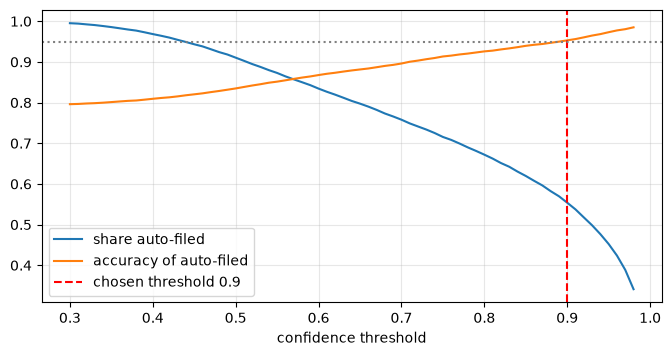

{'confidence_threshold': 0.9,
 'expected_coverage': 0.5538545382481174,
 'expected_auto_accuracy': 0.9530369442705072,
 'target_accuracy': 0.95,
 'reason': 'lowest threshold with dev auto-accuracy >= 95%',
 'test_coverage': 0.550931430836306,
 'test_auto_accuracy': 0.9512589928057554}

In [29]:
curve = pd.read_csv(ARTIFACTS / CHAMP / "reports" / "routing_curve_dev.csv")
policy = read_json(ARTIFACTS / CHAMP / "routing_policy.json")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(curve.threshold, curve.coverage, label="share auto-filed")
ax.plot(curve.threshold, curve.auto_accuracy, label="accuracy of auto-filed")
ax.axvline(policy["confidence_threshold"], color="red", ls="--", label=f"chosen threshold {policy['confidence_threshold']}")
ax.axhline(0.95, color="grey", ls=":")
ax.set_xlabel("confidence threshold"); ax.legend(); ax.grid(alpha=0.3)
plt.show()
policy

The filter used for the `auto.csv` / `manual.csv` split goes beyond confidence. A title is routed to an editor if **any** of these hold:

* confidence below the calibrated threshold
* more than half its tokens are out of vocabulary
* it looks non-English (high OOV and almost no English function words)

In [30]:
from newsclf.pipelines import route

summary = route(cfg, ROOT / metrics[CHAMP]["data_dir"] / "dev.csv", url=BASE)
summary

13:35:57 | INFO    | newsclf.pipelines | Routed 20184 titles: 55.3% automated


{'total': 20184,
 'auto': 11155,
 'manual': 9029,
 'automation_rate': 0.5527,
 'manual_reasons': {'low_confidence': 9007,
  'high_oov_rate': 58,
  'input_not_english': 51},
 'auto_accuracy': 0.953,
 'manual_accuracy_if_automated': 0.5959,
 'model_version': 2,
 'policy': {'confidence_threshold': 0.9,
  'margin_threshold': 0.0,
  'max_oov_rate': 0.5,
  'block_non_english': True}}

In [31]:
pd.read_csv(REPORTS / "routing" / "manual.csv").head(8)[["title", "topic", "predicted_topic", "confidence", "reason"]]

,title,topic,predicted_topic,confidence,reason
0,The coldest computers in the world,WORLD,SCIENCE,0.5234,low_confidence
1,Kailh Silent Box Red Mechanical Keyboard Switches Review: Smooth and Light,TECHNOLOGY,TECHNOLOGY,0.8742,low_confidence
2,Global COVID-19 cases top 21.3mn: Johns Hopkins,HEALTH,WORLD,0.5584,low_confidence
3,A Summer Camp Covid-19 Outbreak Offers Back-to-School Lessons,HEALTH,HEALTH,0.6163,low_confidence
4,Panicked shoppers crowd Auckland supermarkets after new Covid-19 cases announced,WORLD,NATION,0.3453,low_confidence
5,shoprite to leave nigeria,BUSINESS,BUSINESS,0.7510,low_confidence
6,Top singer-songwriter blasts ‘dictator’ Netanyahu for shutting culture venues,NATION,WORLD,0.4356,low_confidence
7,Victims of Beirut's explosion begin sifting through the rubble as hundreds of thousands face homelessness,WORLD,WORLD,0.8725,low_confidence


Over half of incoming articles get filed with no human touch at ~95% precision, while the ones the model would have gotten wrong ~40% of the time go to editors. That is the business metric from Scoping.

### 5.6 Shut down the local server

In [32]:
server.terminate()
server.wait(timeout=10)
print("server stopped")

server stopped


### 5.7 Running real TensorFlow Serving locally

The same `serving/models/` folder is what TF Serving consumes:

```bash
newsclf deploy                                        # versions + generated configs
docker compose -f serving/docker-compose.yml up -d    # tensorflow/serving on :8501
newsclf canary-check --url http://localhost:8501 --promote
curl -d '{"instances": ["NASA launches new telescope"]}' \
     -X POST http://localhost:8501/v1/models/newsapp_model/labels/stable:predict
docker compose -f serving/docker-compose.yml down
```

On Linux with the APT package, `serving/run_tf_serving_native.sh` starts `tensorflow_model_server` against the native config instead. To start over, `newsclf deploy` wipes and rebuilds the serving folder.

## 6. Monitoring

Shipping is the start of the maintenance job. Concept drift (an athlete becomes a celebrity) and data drift (a new name or source appears) both erode performance quietly, so three families of metrics are tracked:

* **Software:** latency, throughput, memory, error rate (TF Serving exposes these; `/health` on the local server).
* **Input:** title length, out-of-vocabulary rate, English function-word ratio, share of non-English titles, length-distribution shift (PSI) versus training.
* **Output:** topic mix, mean confidence, share routed to editors, agreement with the previous model.

Here they run against the production log the prototype wrote (`news_articles.db`), whose stored softmax scores are decoded from float32 blobs.

13:35:58 | WARNING | newsclf.pipelines | ALARM: Rolling OOV rate (window=10) breached threshold from row 102
13:35:58 | WARNING | newsclf.pipelines | ALARM: 5 titles look non-English - check the source feed


alarms:
  - Rolling OOV rate (window=10) breached threshold from row 102
  - 5 titles look non-English - check the source feed
PSI (title length): 0.1869 | PSI (OOV rate): 0.2615


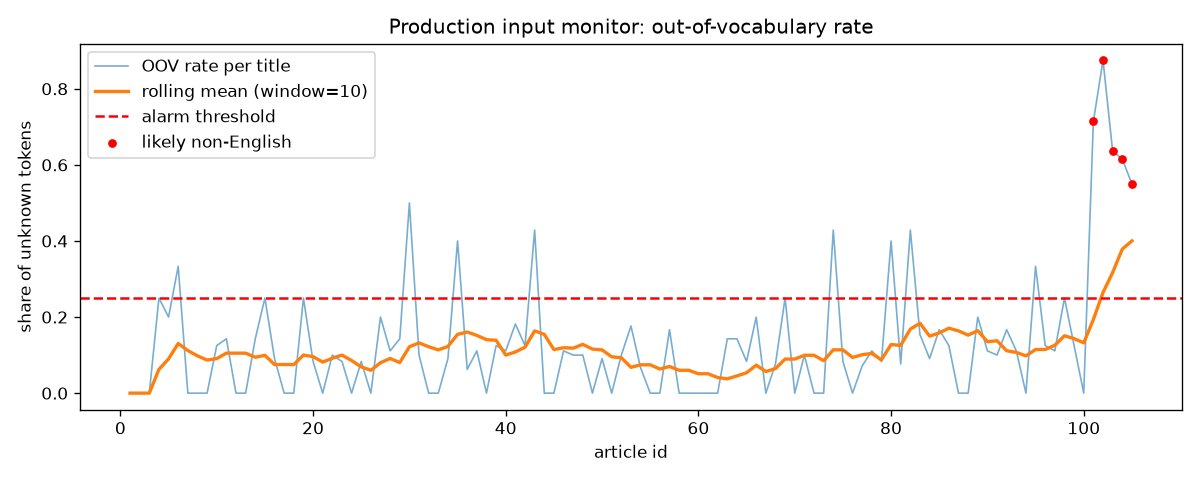

In [33]:
from newsclf.pipelines import monitor

mon = monitor(cfg)
print("alarms:")
for a in mon["inputs"]["alarms"]:
    print("  -", a)
print("PSI (title length):", mon["inputs"].get("psi_n_tokens"), "| PSI (OOV rate):", mon["inputs"].get("psi_oov_rate"))
display(Image(filename=str(REPORTS / "monitoring" / "oov_trend.png"), width=820))

In [34]:
pd.read_csv(REPORTS / "monitoring" / "flagged_inputs.csv")

,id,title,domain
0,101,L’appello di Renzi a Meloni: «Riporta a casa Ilaria Salis e ti applaudiremo». Sul palco della Leopolda il padre dell...,corriere.it
1,102,"Una nonna sul trattore, grano, ulivi e un omaggio floreale. Ecco l'8 marzo delle donne Coldiretti",corriere.it
2,103,Fuga di notizie: ma i magistrati fanno sempre il loro dovere?,corriere.it
3,104,Una folla oceanica di oltre 2 milioni di persone alla manifestazione pro Gaza,corriere.it
4,105,"Ucraina Russia, le notizie sulla guerra di oggi | Zelensky a Istanbul incontra Erdogan: «Turchia pronta a ospitare c...",corriere.it


The OOV alarm fires at the end of the log: a feed from `corriere.it` started sending Italian headlines. The prototype scored them anyway and they would have gone straight into users' feeds with confident-looking but meaningless topics. With the new system:

1. The language guard routes them to `manual` instead of auto-filing (seen in 5.5).
2. The alarm points at the source domain, so the ingestion team can filter or tag the feed.
3. If the business wants Italian coverage, that is a new data-collection project, not a threshold tweak.

The runbook for each alarm is in `docs/RUNBOOK.md`.

## 7. Wrap-up and recommendations

**Where things stand**

In [35]:
summary_rows = []
for e in ["E1", "E2", "E3", CHAMP, "B1", "E8"]:
    m = metrics[e]
    summary_rows.append({"experiment": e, "what": m["description"][:70], "test_acc": m["test"]["accuracy"],
                         "test_macro_f1": m["test"]["macro_f1"], "promotable": m.get("promotable")})
pd.DataFrame(summary_rows).drop_duplicates("experiment").round(4)

,experiment,what,test_acc,test_macro_f1,promotable
0,E1,Inherited prototype re-measured on its own test file,0.7778,0.7681,False
1,E2,"Stratified 60/20/20 re-split of legacy data, prototype architecture, n",0.8146,0.8135,False
2,E3,"Repaired BUSINESS titles + de-duplicated leak-free split, prototype ar",0.7543,0.7527,True
3,E4,"Pooled embedding model, 20k vocab, dropout, balanced class weights, ea",0.7951,0.7946,True
4,B1,TF-IDF word(1-2)+char(3-5) n-grams + logistic regression,0.8189,0.8210,False
5,E8,"E4 setup with merged taxonomy (WORLD+NATION, SCIENCE+TECHNOLOGY) - sta",0.8456,0.8448,False


**Recommendations to the product owner**

1. **Labelling guidelines first.** WORLD vs NATION and SCIENCE vs TECHNOLOGY drive most errors. Either write deterministic tie-break rules, move to multi-label annotation, or merge the topics (E8 quantifies the gain). Inter-rater agreement should be measured so that the true ceiling is known.
2. **Allow an article to sit under two topics in the app.** The model's top-2 accuracy is ~91%; surfacing the second topic captures most of the remaining value.
3. **Recover the original BUSINESS titles** (backup file or publisher feeds). Slug reconstruction works, but real headlines remove a known distortion. Drop the file in `data/raw/` and set `data.reference_titles_file`.
4. **Collect more SCIENCE articles** rather than relying on synthetic augmentation.
5. **Run with a human in the loop** at the calibrated threshold (~55% of articles fully automated at ~95% precision) and track the manual queue size as a KPI.
6. **Add a source-language check at ingestion** and keep the OOV alarm on.

**Next iteration (2-3 weeks):** add article body or description as a feature; try a small pre-trained transformer (GPU recommended); port the strong TF-IDF baseline into the TF graph so it can be served; schedule weekly re-training with the canary gate in CI.